# Chapitre 4 - Méthodes linéaires de classification
## Cours 1 : régression sur indicatrices, LDA et QDA

Ce premier notebook couvre les sections 4.1 à 4.3.2 du livre :

1. le cadre de la classification et la notion de **frontière de décision linéaire** ;
2. la **régression linéaire sur la matrice indicatrice** et le phénomène de **masquage**
   (figures 4.2 et 4.3 du livre) ;
3. l'**analyse discriminante linéaire** (LDA) déduite du modèle gaussien et de la formule
   de Bayes (figure 4.5) ;
4. l'**analyse discriminante quadratique** (QDA) et sa version régularisée (RDA)
   (figures 4.6 et 4.7) ;
5. la comparaison de ces méthodes sur les données de voyelles (tableau 4.1).

La LDA de rang réduit fait l'objet du cours 2, la régression logistique et les hyperplans
séparateurs du cours 3.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch04_classification as c4
set_style()

## 1. Le problème de classification

On observe des couples $(x_i, g_i)$, $i = 1, \dots, N$, où $x_i \in \mathbb{R}^p$ est un
vecteur de prédicteurs et $g_i \in \mathcal{G} = \{1, \dots, K\}$ une **classe**. Un
classifieur est une fonction $\hat G : \mathbb{R}^p \to \mathcal{G}$ ; il découpe l'espace
des entrées en $K$ **régions de décision**, séparées par des **frontières de décision**.

Dans ce chapitre, les frontières sont **linéaires** : ce sont des morceaux d'hyperplans
affines $\{x : \beta_0 + \beta^T x = 0\}$.

Le cas typique : on dispose d'une **fonction discriminante** $\delta_k(x)$ par classe et on
classe vers la plus grande,
$$\hat G(x) = \operatorname*{arg\,max}_{k} \delta_k(x).$$
La frontière entre les classes $k$ et $\ell$ est $\{x : \delta_k(x) = \delta_\ell(x)\}$ ;
si chaque $\delta_k$ est affine en $x$, $\delta_k(x) = \beta_{k0} + \beta_k^T x$, alors cette
frontière est l'hyperplan $\{x : (\beta_{k0} - \beta_{\ell 0}) + (\beta_k - \beta_\ell)^T x = 0\}$.

> **Remarque.** Il suffit en fait qu'une **transformation monotone** de $\delta_k$ (ou de
> $\Pr(G = k \mid X = x)$) soit affine. Par exemple, pour la régression logistique à deux
> classes, c'est le logarithme du rapport des chances $\log \frac{p}{1-p}$ qui est affine
> (éq. (4.1)-(4.2) du livre).

> **Intuition.** On peut aussi obtenir des frontières *non linéaires* avec ces méthodes en
> enrichissant les entrées : en ajoutant $x_1^2, x_2^2, x_1 x_2$, une frontière linéaire
> dans l'espace augmenté (dimension 5) devient une **conique** dans le plan d'origine.
> Nous l'illustrerons plus bas (figure 4.6).

## 2. Régression linéaire d'une matrice indicatrice (section 4.2)

On code chaque réponse par un vecteur indicateur $y_i = (y_{i1}, \dots, y_{iK})$ avec
$y_{ik} = 1$ si $g_i = k$ et $0$ sinon. On empile ces vecteurs dans la **matrice
indicatrice** $\mathbf{Y}$ de taille $N \times K$ (une seule valeur 1 par ligne).

On ajuste simultanément les $K$ régressions linéaires par moindres carrés
(éq. (4.3) du livre) :
$$\hat{\mathbf{Y}} = \mathbf{X} (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{Y},
\qquad \hat{\mathbf{B}} = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{Y},$$
où $\mathbf{X}$ ($N \times (p+1)$) contient une première colonne de 1.

Une nouvelle entrée $x$ est classée en calculant le vecteur ajusté
$\hat f(x)^T = (1, x^T)\hat{\mathbf{B}}$ (de taille $K$) puis
$$\hat G(x) = \operatorname*{arg\,max}_{k} \hat f_k(x) \qquad \text{(éq. (4.4) du livre).}$$

**Justification.** $\hat f_k(x)$ estime $\mathbb{E}(Y_k \mid X = x) = \Pr(G = k \mid X = x)$,
puisque $Y_k$ vaut 1 exactement quand $G = k$. Classer vers la plus grande composante revient
donc à imiter la règle de Bayes.

**Propriété : les composantes ajustées somment à 1.** En effet,
$\hat{\mathbf{Y}} \mathbf{1}_K = \mathbf{H} \mathbf{Y} \mathbf{1}_K$ avec
$\mathbf{H} = \mathbf{X}(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T$ la matrice de projection
orthogonale sur l'espace engendré par les colonnes de $\mathbf{X}$.

- Chaque ligne de $\mathbf{Y}$ contient exactement un 1, donc $\mathbf{Y}\mathbf{1}_K = \mathbf{1}_N$.
- $\mathbf{1}_N$ est la première colonne de $\mathbf{X}$, donc il est laissé fixe par la
  projection : $\mathbf{H}\mathbf{1}_N = \mathbf{1}_N$.

Ainsi $\hat{\mathbf{Y}}\mathbf{1}_K = \mathbf{1}_N$ : pour tout $x$, $\sum_k \hat f_k(x) = 1$.

> **Remarque.** Ce ne sont pas pour autant des probabilités : rien n'empêche $\hat f_k(x)$
> d'être négatif ou supérieur à 1, surtout loin des données (la régression est linéaire et
> donc non bornée).

### Le masquage (figures 4.2 et 4.3 du livre)

On simule trois classes gaussiennes de même covariance $\mathbf{I}_2$, dont les centres sont
**alignés** sur la diagonale du plan. Les classes sont presque parfaitement séparables par
deux droites parallèles. Nous comparons la régression sur indicatrices et la LDA.

In [2]:
rng = np.random.RandomState(0)
n_per = 150
d = 4.2                                   # distance entre centres voisins
u = np.array([1.0, 1.0]) / np.sqrt(2)     # direction de la droite des centres
centres = np.array([-d * u, 0 * u, d * u])
X_mask = np.vstack([rng.randn(n_per, 2) + c for c in centres])
g_mask = np.repeat([1, 2, 3], n_per)
X_mask.shape

(450, 2)

In [3]:
reg_mask = c4.indicator_regression_fit(X_mask, g_mask)
lda_mask = c4.lda_fit(X_mask, g_mask)
err_reg = c4.error_rate(g_mask, c4.indicator_regression_predict(reg_mask, X_mask))
err_lda = c4.error_rate(g_mask, c4.lda_predict(lda_mask, X_mask))
print("Erreur d'apprentissage  régression : %.3f   LDA : %.3f" % (err_reg, err_lda))
print("Classe 2 prédite par la régression :",
      np.sum(c4.indicator_regression_predict(reg_mask, X_mask) == 2), "fois")

Erreur d'apprentissage  régression : 0.333   LDA : 0.033
Classe 2 prédite par la régression : 0 fois


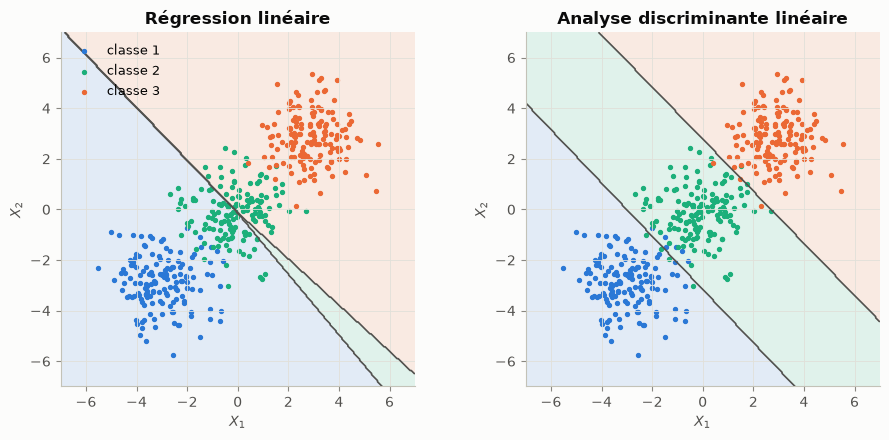

In [4]:
cls3 = [BLUE, COLORS[2], ORANGE]
lim = (-7, 7)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (nom, pred) in zip(axes, [
        ("Régression linéaire", lambda Z: c4.indicator_regression_predict(reg_mask, Z)),
        ("Analyse discriminante linéaire", lambda Z: c4.lda_predict(lda_mask, Z))]):
    c4.plot_decision_regions(ax, pred, lim, lim, [1, 2, 3], cls3)
    for k in range(3):
        ax.scatter(*X_mask[g_mask == k + 1].T, s=8, color=cls3[k], label="classe %d" % (k + 1))
    ax.set_title(nom)
    ax.set_xlabel("$X_1$")
    ax.set_ylabel("$X_2$")
    ax.set_aspect("equal")
axes[0].legend(loc="upper left")
plt.show()

À gauche, la classe centrale (verte) **n'est jamais prédite** : elle est *masquée* par les
deux autres. La LDA (à droite) trouve les deux frontières attendues.

Pour comprendre, projetons les données sur la droite des centres (la direction orthogonale
ne contient aucune information ici) et traçons les trois régressions des indicatrices sur
cette coordonnée, d'abord linéaires puis quadratiques.

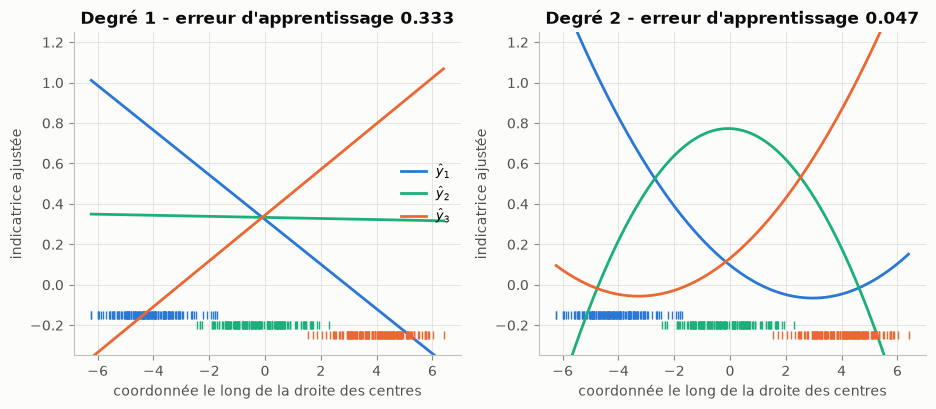

In [5]:
t = X_mask @ u                       # coordonnée le long de la droite des centres
Y_mask = c4.indicator_matrix(g_mask)
tt = np.linspace(t.min(), t.max(), 300)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, deg in zip(axes, [1, 2]):
    P = np.vander(t, deg + 1)
    coefs = np.linalg.lstsq(P, Y_mask, rcond=None)[0]
    fit_grid = np.vander(tt, deg + 1) @ coefs
    err = np.mean(np.argmax(P @ coefs, axis=1) + 1 != g_mask)
    for k in range(3):
        ax.plot(tt, fit_grid[:, k], color=cls3[k], label="$\\hat y_{%d}$" % (k + 1))
        ax.plot(t[g_mask == k + 1], np.full(n_per, -0.15 - 0.05 * k), "|", color=cls3[k], ms=6)
    ax.set_title("Degré %d - erreur d'apprentissage %.3f" % (deg, err))
    ax.set_xlabel("coordonnée le long de la droite des centres")
    ax.set_ylabel("indicatrice ajustée")
    ax.set_ylim(-0.35, 1.25)
axes[0].legend(loc="center right")
plt.show()

Avec un ajustement **linéaire**, la droite de la classe 2 est quasiment **horizontale**
(autour de $1/3$, la proportion de cette classe) : elle n'est jamais au-dessus des deux
autres. Le degré 2 suffit ici à faire « remonter » l'indicatrice centrale.

> **À retenir.** Avec $K$ classes alignées, il faudrait des polynômes de degré $K-1$ pour
> éviter le masquage, soit $O(p^{K-1})$ termes en dimension $p$. Le masquage est fréquent
> quand $K$ est grand et $p$ petit. Les méthodes suivantes (LDA, logistique) utilisent
> aussi des fonctions linéaires de $x$, mais d'une manière qui évite ce problème.

## 3. Analyse discriminante linéaire (section 4.3)

### Formule de Bayes

Notons $f_k$ la densité de $X$ dans la classe $k$ et $\pi_k = \Pr(G = k)$ la probabilité
*a priori* de la classe ($\sum_k \pi_k = 1$). La formule de Bayes donne (éq. (4.7) du livre)
$$\Pr(G = k \mid X = x) = \frac{f_k(x)\, \pi_k}{\sum_{\ell=1}^K f_\ell(x)\, \pi_\ell}.$$
Le dénominateur ne dépend pas de $k$ : pour classer, il suffit de comparer les
$f_k(x)\pi_k$.

### Le modèle gaussien à covariance commune

On suppose (éq. (4.8)) chaque classe gaussienne multivariée,
$$f_k(x) = \frac{1}{(2\pi)^{p/2} |\Sigma_k|^{1/2}}
\exp\!\Big(-\tfrac12 (x - \mu_k)^T \Sigma_k^{-1} (x - \mu_k)\Big),$$
et, pour la LDA, que **toutes les classes partagent la même covariance** :
$\Sigma_k = \Sigma$ pour tout $k$.

**Le log-rapport est affine.** Calculons pas à pas
$\log \frac{\Pr(G=k\mid X=x)}{\Pr(G=\ell\mid X=x)} = \log\frac{f_k(x)}{f_\ell(x)} + \log\frac{\pi_k}{\pi_\ell}$.
Les constantes de normalisation sont identiques (même $\Sigma$) et se simplifient :
$$\log\frac{f_k(x)}{f_\ell(x)} = -\tfrac12 (x-\mu_k)^T\Sigma^{-1}(x-\mu_k) + \tfrac12 (x-\mu_\ell)^T\Sigma^{-1}(x-\mu_\ell).$$
On développe chaque forme quadratique :
$(x-\mu)^T\Sigma^{-1}(x-\mu) = x^T\Sigma^{-1}x - 2x^T\Sigma^{-1}\mu + \mu^T\Sigma^{-1}\mu$
(car $\Sigma^{-1}$ est symétrique). Les termes $x^T\Sigma^{-1}x$ **se compensent** et il reste
$$\log\frac{\Pr(G=k\mid x)}{\Pr(G=\ell\mid x)} = \log\frac{\pi_k}{\pi_\ell}
- \tfrac12 (\mu_k+\mu_\ell)^T\Sigma^{-1}(\mu_k-\mu_\ell) + x^T\Sigma^{-1}(\mu_k-\mu_\ell),$$
expression **affine en $x$** (éq. (4.9) du livre).

On en déduit les **fonctions discriminantes linéaires** (éq. (4.10)) : en gardant dans
$\log(f_k(x)\pi_k)$ seulement les termes qui dépendent de $k$,
$$\delta_k(x) = x^T\Sigma^{-1}\mu_k - \tfrac12 \mu_k^T\Sigma^{-1}\mu_k + \log\pi_k,
\qquad \hat G(x) = \operatorname*{arg\,max}_k \delta_k(x).$$

En pratique on remplace les paramètres par leurs estimations :
- $\hat\pi_k = N_k / N$ où $N_k$ est l'effectif de la classe $k$ ;
- $\hat\mu_k = \frac{1}{N_k}\sum_{g_i = k} x_i$ ;
- $\hat\Sigma = \frac{1}{N-K}\sum_{k=1}^K \sum_{g_i=k} (x_i - \hat\mu_k)(x_i-\hat\mu_k)^T$
  (covariance **intra-classe** commune).

### Illustration : frontières de Bayes et frontières estimées (figure 4.5)

Trois gaussiennes de même covariance. À gauche, les vraies densités (ellipses contenant 95 %
de la masse) et les frontières de Bayes ; à droite, un échantillon de 30 points par classe,
les frontières de la LDA estimée (traits pleins) et celles de Bayes (pointillés).

In [6]:
mu_true = np.array([[0.0, 0.0], [2.5, 0.5], [1.0, 2.5]])
Sigma_true = np.array([[1.0, 0.5], [0.5, 1.0]])
model_bayes = {"classes": np.array([0, 1, 2]), "priors": np.ones(3) / 3,
               "means": mu_true, "cov": Sigma_true}
rng = np.random.RandomState(0)
Lc = np.linalg.cholesky(Sigma_true)
X45 = np.vstack([rng.randn(30, 2) @ Lc.T + m for m in mu_true])
g45 = np.repeat([0, 1, 2], 30)
lda45 = c4.lda_fit(X45, g45)

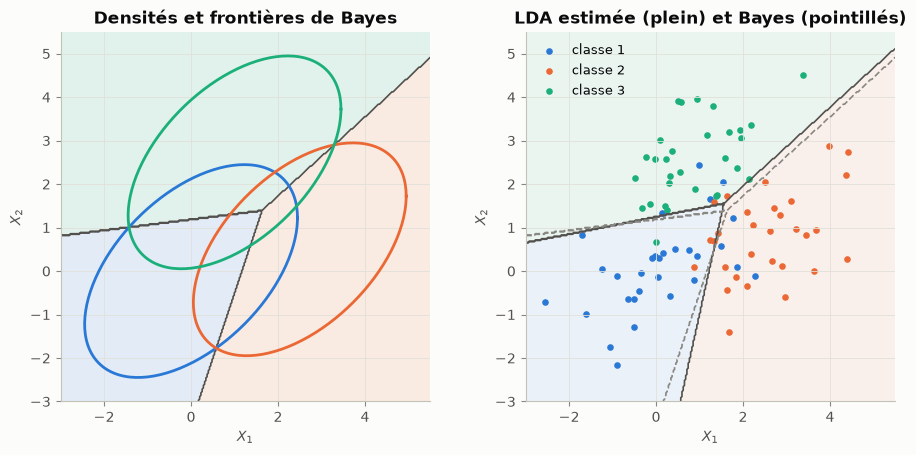

In [7]:
from esl.plotting import decision_grid
lim45 = ((-3, 5.5), (-3, 5.5))
theta = np.linspace(0, 2 * np.pi, 200)
ellipse = np.sqrt(5.991) * np.c_[np.cos(theta), np.sin(theta)] @ Lc.T   # quantile 95 % du chi2(2)
cls3b = [BLUE, ORANGE, COLORS[2]]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
c4.plot_decision_regions(axes[0], lambda Z: c4.lda_predict(model_bayes, Z), *lim45, [0, 1, 2], cls3b)
for k in range(3):
    axes[0].plot(*(ellipse + mu_true[k]).T, color=cls3b[k])
axes[0].set_title("Densités et frontières de Bayes")
c4.plot_decision_regions(axes[1], lambda Z: c4.lda_predict(lda45, Z), *lim45, [0, 1, 2], cls3b,
                         alpha=0.08)
xx, yy, grid = decision_grid(*lim45, n=300)
lab = c4.lda_predict(model_bayes, grid).reshape(xx.shape)
axes[1].contour(xx, yy, lab, levels=[0.5, 1.5], colors=GRAY, linestyles="--", linewidths=1.2)
for k in range(3):
    axes[1].scatter(*X45[g45 == k].T, s=14, color=cls3b[k], label="classe %d" % (k + 1))
axes[1].set_title("LDA estimée (plein) et Bayes (pointillés)")
axes[1].legend(loc="upper left")
for ax in axes:
    ax.set_xlabel("$X_1$")
    ax.set_ylabel("$X_2$")
    ax.set_aspect("equal")
plt.show()

Les frontières de Bayes sont des demi-droites qui se coupent en un point : chacune est
l'ensemble où deux fonctions $\delta_k$ sont égales **et** dominent la troisième.
Avec 90 observations, l'estimation est déjà proche de la règle optimale.

### Le cas de deux classes

Avec $K = 2$, la LDA classe vers la classe 2 si $\delta_2(x) > \delta_1(x)$, c'est-à-dire
(en réarrangeant (4.9))
$$x^T\hat\Sigma^{-1}(\hat\mu_2-\hat\mu_1) > \tfrac12(\hat\mu_2+\hat\mu_1)^T\hat\Sigma^{-1}(\hat\mu_2-\hat\mu_1) - \log(N_2/N_1).$$
La direction $\hat\Sigma^{-1}(\hat\mu_2 - \hat\mu_1)$ est **la même** que celle des
moindres carrés quand on code les deux classes par deux valeurs numériques (exercice 4.2) ;
seul le seuil diffère lorsque $N_1 \ne N_2$.

> **Remarque (au-delà du modèle gaussien).** La direction de la LDA à deux classes ne
> dépend que des moyennes et de la covariance : elle garde un sens même sans hypothèse
> gaussienne. En revanche le seuil (le point de coupure) en dépend ; on peut alors le
> choisir pour minimiser l'erreur d'apprentissage.

## 4. Analyse discriminante quadratique (QDA)

Si l'on **ne suppose plus** les $\Sigma_k$ égales, les termes $x^T\Sigma_k^{-1}x$ ne se
compensent plus. En gardant tout ce qui dépend de $k$ dans $\log(f_k(x)\pi_k)$ on obtient
les **fonctions discriminantes quadratiques** (éq. (4.12) du livre)
$$\delta_k(x) = -\tfrac12\log|\Sigma_k| - \tfrac12(x-\mu_k)^T\Sigma_k^{-1}(x-\mu_k) + \log\pi_k.$$
Les frontières $\{\delta_k = \delta_\ell\}$ sont des **quadriques** (coniques dans le plan).

> **Coût en paramètres.** La QDA estime une matrice $p\times p$ symétrique par classe,
> soit $K\,p(p+1)/2$ paramètres de covariance au lieu de $p(p+1)/2$ pour la LDA.

### Deux façons d'obtenir des frontières quadratiques (figure 4.6)

On compare : (i) la QDA ; (ii) la LDA appliquée dans l'espace augmenté de dimension 5
$(X_1, X_2, X_1X_2, X_1^2, X_2^2)$. On simule trois classes de covariances différentes.

In [8]:
rng = np.random.RandomState(1)
covs46 = [np.array([[1.0, 0.0], [0.0, 0.3]]),
          np.array([[0.4, -0.3], [-0.3, 1.2]]),
          np.array([[2.0, 0.8], [0.8, 0.7]])]
mu46 = np.array([[0.0, 0.0], [2.0, 2.0], [-1.0, 2.5]])
X46 = np.vstack([rng.randn(100, 2) @ np.linalg.cholesky(S).T + m for S, m in zip(covs46, mu46)])
g46 = np.repeat([0, 1, 2], 100)

def quad_features(X):
    """Entrées augmentées (X1, X2, X1 X2, X1^2, X2^2)."""
    return np.column_stack([X, X[:, 0] * X[:, 1], X[:, 0] ** 2, X[:, 1] ** 2])

qda46 = c4.qda_fit(X46, g46)
lda46q = c4.lda_fit(quad_features(X46), g46)
print("Erreur d'apprentissage  QDA : %.3f   LDA quadratique : %.3f" % (
    c4.error_rate(g46, c4.qda_predict(qda46, X46)),
    c4.error_rate(g46, c4.lda_predict(lda46q, quad_features(X46)))))

Erreur d'apprentissage  QDA : 0.073   LDA quadratique : 0.073


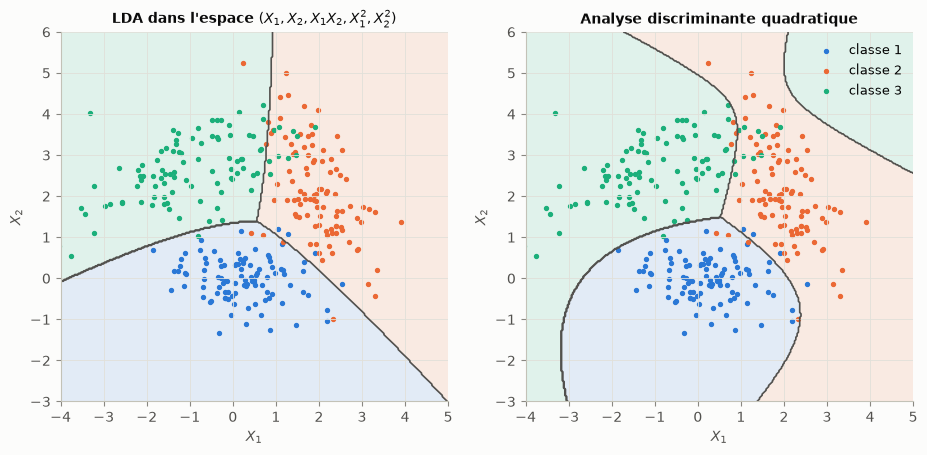

In [9]:
lim46 = ((-4, 5), (-3, 6))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, (nom, pred) in zip(axes, [
        ("LDA dans l'espace $(X_1, X_2, X_1X_2, X_1^2, X_2^2)$",
         lambda Z: c4.lda_predict(lda46q, quad_features(Z))),
        ("Analyse discriminante quadratique", lambda Z: c4.qda_predict(qda46, Z))]):
    c4.plot_decision_regions(ax, pred, *lim46, [0, 1, 2], cls3b)
    for k in range(3):
        ax.scatter(*X46[g46 == k].T, s=8, color=cls3b[k], label="classe %d" % (k + 1))
    ax.set_title(nom, fontsize=10)
    ax.set_xlabel("$X_1$")
    ax.set_ylabel("$X_2$")
axes[1].legend(loc="upper right")
plt.show()

Comme dans le livre, les deux frontières sont très proches **là où se trouvent les
données** (et les erreurs d'apprentissage coïncident) ; elles ne divergent que loin des
observations, où rien ne les contraint. La LDA augmentée est une règle *linéaire en 5
dimensions*, la QDA une règle *quadratique en 2 dimensions* : toutes deux produisent des
frontières coniques, mais estimées différemment (covariance commune dans l'espace augmenté
d'un côté, une covariance par classe de l'autre).

## 5. Analyse discriminante régularisée (RDA)

Friedman (1989) propose un compromis entre LDA et QDA en « rétrécissant » les covariances
de classe vers la covariance commune (éq. (4.13) du livre) :
$$\hat\Sigma_k(\alpha) = \alpha\,\hat\Sigma_k + (1-\alpha)\,\hat\Sigma, \qquad \alpha\in[0,1].$$
$\alpha = 0$ redonne la LDA, $\alpha = 1$ la QDA ; en pratique $\alpha$ se choisit sur un
échantillon de validation ou par validation croisée.

Nous l'appliquons aux **données de voyelles** : $K = 11$ voyelles de l'anglais prononcées
par plusieurs locuteurs, décrites par $p = 10$ caractéristiques acoustiques ; 528
observations d'apprentissage et 462 de test (locuteurs différents).

In [10]:
Xtr, ytr = datasets.load_vowel("train")
Xte, yte = datasets.load_vowel("test")
print(Xtr.shape, Xte.shape, "classes :", np.unique(ytr))

(528, 10) (462, 10) classes : [ 1  2  3  4  5  6  7  8  9 10 11]


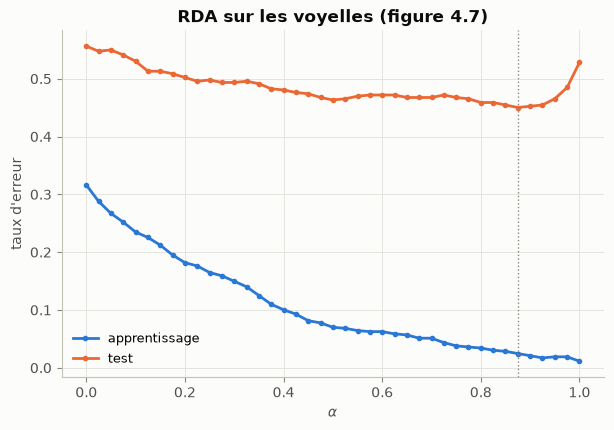

Meilleur alpha (test) : 0.875, erreur de test 0.450


In [11]:
alphas = np.linspace(0, 1, 41)
err_rda = np.array([[c4.error_rate(y, c4.qda_predict(c4.qda_fit(Xtr, ytr, alpha=a), X))
                     for (X, y) in [(Xtr, ytr), (Xte, yte)]] for a in alphas])
a_best = alphas[np.argmin(err_rda[:, 1])]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(alphas, err_rda[:, 0], "o-", ms=3, color=BLUE, label="apprentissage")
ax.plot(alphas, err_rda[:, 1], "o-", ms=3, color=ORANGE, label="test")
ax.axvline(a_best, color=GRAY, ls=":", lw=1)
ax.set_title("RDA sur les voyelles (figure 4.7)")
ax.set_xlabel(r"$\alpha$")
ax.set_ylabel("taux d'erreur")
ax.legend()
plt.show()
print("Meilleur alpha (test) : %.3f, erreur de test %.3f" % (a_best, err_rda[:, 1].min()))

L'erreur de test est minimale pour $\alpha$ proche de $0{,}9$, nettement en dessous des
extrémités LDA ($\alpha=0$) et QDA ($\alpha=1$) : la régularisation paie.

> **Remarque.** Choisir $\alpha$ en regardant l'erreur *de test*, comme dans la figure 4.7
> du livre, est un raccourci d'illustration : une vraie procédure choisirait $\alpha$ par
> validation croisée sur l'échantillon d'apprentissage seul (chapitre 7).

## 6. Calculs pratiques : la LDA comme « centroïde le plus proche » après blanchiment

Écrivons la décomposition spectrale $\hat\Sigma = \mathbf{U}\mathbf{D}\mathbf{U}^T$
($\mathbf{U}$ orthogonale, $\mathbf{D}$ diagonale positive). Posons
$X^* = \mathbf{D}^{-1/2}\mathbf{U}^T X$ : alors $\operatorname{Cov}(X^*) = \mathbf{I}$
(on dit que les données sont **blanchies**, ou « sphérisées »). Dans ces coordonnées,
$(x-\mu_k)^T\hat\Sigma^{-1}(x-\mu_k) = \|x^* - \mu_k^*\|^2$.

La règle LDA devient donc (section 4.3.2 du livre) : **classer vers le centroïde le plus
proche dans l'espace blanchi**, à la correction $\log \pi_k$ près :
$$\hat G(x) = \operatorname*{arg\,min}_k \Big(\tfrac12\|x^*-\mu_k^*\|^2 - \log\pi_k\Big).$$
Vérifions numériquement sur les voyelles.

In [ ]:
lda_v = c4.lda_fit(Xtr, ytr)
dvals, U = np.linalg.eigh(lda_v["cov"])
Wh = U / np.sqrt(dvals)                     # matrice de blanchiment U D^{-1/2}
Zte, Mz = Xte @ Wh, lda_v["means"] @ Wh
d2 = ((Zte[:, None, :] - Mz[None]) ** 2).sum(axis=2)
pred_sphere = lda_v["classes"][np.argmin(0.5 * d2 - np.log(lda_v["priors"]), axis=1)]
print("Covariance blanchie ≈ I :", np.allclose(Wh.T @ lda_v["cov"] @ Wh, np.eye(10)))
print("Mêmes prédictions que la LDA :", np.array_equal(pred_sphere, c4.lda_predict(lda_v, Xte)))

## 7. Comparaison sur les voyelles (tableau 4.1 du livre)

On ajoute la régression logistique multinomiale (cours 3 et exercice 4.4), ajustée par
Newton-Raphson avec la fonction `multilogit_newton` du module.

In [ ]:
reg_v = c4.indicator_regression_fit(Xtr, ytr)
qda_v = c4.qda_fit(Xtr, ytr)
log_v = c4.multilogit_newton(Xtr, ytr)
predicteurs = {
    "Régression linéaire": lambda X: c4.indicator_regression_predict(reg_v, X),
    "Analyse discriminante linéaire": lambda X: c4.lda_predict(lda_v, X),
    "Analyse discriminante quadratique": lambda X: c4.qda_predict(qda_v, X),
    "Régression logistique": lambda X: c4.multilogit_predict(log_v, X),
}
table41 = pd.DataFrame({nom: [c4.error_rate(ytr, f(Xtr)), c4.error_rate(yte, f(Xte))]
                        for nom, f in predicteurs.items()},
                       index=["apprentissage", "test"]).T.round(2)
table41

Nous retrouvons exactement le tableau 4.1 du livre : $0{,}48/0{,}67$ pour la régression,
$0{,}32/0{,}56$ pour la LDA, $0{,}01/0{,}53$ pour la QDA et $0{,}22/0{,}51$ pour la
logistique. La régression linéaire souffre du **masquage** : elle perd plus de 10 points
par rapport à la LDA, pourtant fondée elle aussi sur des fonctions linéaires de $x$.